# 02 · Análisis exploratorio de datos (EDA)

**Proyecto integrador – Equipo 4** · Responsable: **David**

Parte de la tabla limpia que deja el ETL (`data/processed/ventas_limpias.parquet`). El objetivo es entender **cómo se comporta el negocio** antes de construir el dashboard y el modelo: tendencias, estacionalidad, concentración de productos y clientes, mercados, devoluciones y correlaciones.

Preguntas guía:
1. ¿Cómo evolucionan las ventas y qué tan estacionales son?
2. ¿Qué días y horas concentran los pedidos? ¿Influyen los festivos?
3. ¿Qué tan concentradas están las ventas en pocos productos y clientes?
4. ¿Qué mercados (países) importan además del Reino Unido?
5. ¿Qué tanto se devuelve y qué variables se relacionan entre sí?
6. ¿Qué tan predecible es la demanda semanal de un producto? (insumo para el modelo)

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
from src import visualizacion as viz
viz.aplicar_estilo()

ventas = pd.read_parquet(config.VENTAS_LIMPIAS)
festivos = pd.read_csv(config.FESTIVOS_LIMPIOS, parse_dates=["fecha"])
v = ventas[ventas["tipo_transaccion"] == "Venta"]          # solo ventas
d = ventas[ventas["tipo_transaccion"] == "Devolución"]     # solo devoluciones
print(f"Líneas: {len(ventas):,} | ventas: {len(v):,} | devoluciones: {len(d):,}")

Líneas: 1,021,239 | ventas: 1,003,327 | devoluciones: 17,912


## 1. Estadística descriptiva

In [2]:
ventas[["cantidad", "precio_unitario", "importe"]].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
cantidad,"1,021,239.00",10.39,59.71,"-9,360.00",1.00,3.00,10.00,30.00,100.00,"9,456.00"
precio_unitario,"1,021,239.00",3.36,4.87,0.03,1.25,2.10,4.13,9.95,16.95,"1,157.15"
importe,"1,021,239.00",18.52,77.11,"-6,539.40",3.75,9.95,17.70,59.40,179.00,"38,970.00"


In [3]:
# Nivel factura (pedido): cuántos productos, unidades y libras tiene un pedido típico
pedidos = (v.groupby("factura")
           .agg(fecha=("fecha", "first"), cliente=("cliente_id", "first"), pais=("pais", "first"),
                productos=("codigo_producto", "nunique"), unidades=("cantidad", "sum"),
                importe=("importe", "sum")))
pedidos[["productos", "unidades", "importe"]].describe(percentiles=[.5, .9, .99]).T

,count,mean,std,min,50%,90%,99%,max
productos,"39,513.00",25.11,42.27,1.00,15.00,51.00,196.88,"1,106.00"
unidades,"39,513.00",276.42,967.57,1.00,148.00,522.80,"2,220.28","87,167.00"
importe,"39,513.00",490.49,"1,124.68",0.19,301.20,905.42,"4,089.72","52,940.94"


**Hallazgos.** La distribución es muy asimétrica: la línea típica (mediana) es de 3 unidades y £9,95, pero hay líneas de miles de unidades. Un pedido típico tiene **15 productos distintos, 148 unidades y £301** (mediana); el promedio (£490) es mucho mayor que la mediana, señal de que existen **pedidos mayoristas muy grandes**. Por eso, en adelante se usan medianas y escalas logarítmicas cuando conviene.

## 2. Tendencia y estacionalidad

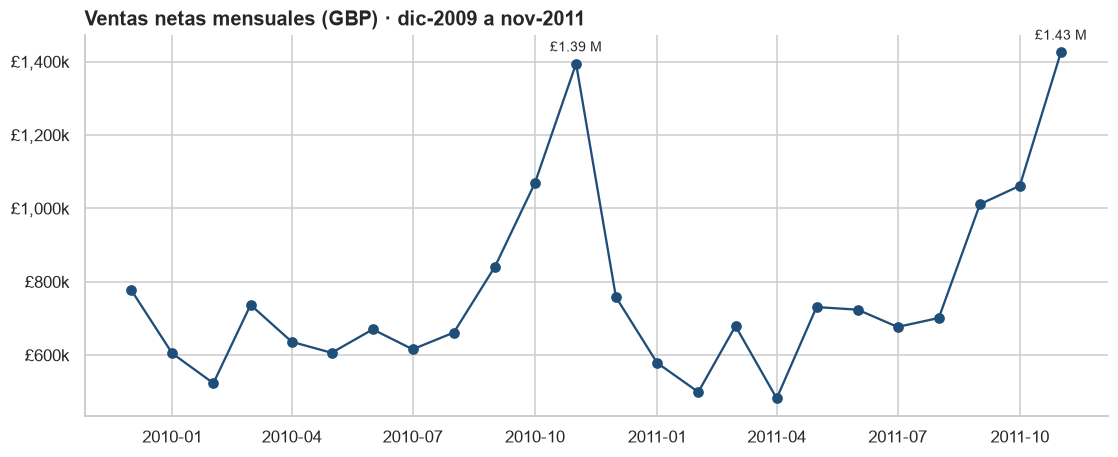

In [4]:
mensual = (ventas.assign(anio_mes=ventas["fecha"].dt.to_period("M"))
           .groupby("anio_mes")
           .agg(ventas_netas=("importe", "sum"),
                pedidos=("factura", lambda s: s[~s.str.startswith("C")].nunique()),
                clientes=("cliente_id", lambda s: s[s != "SIN REGISTRO"].nunique()))
           .reset_index())
mensual["fecha"] = mensual["anio_mes"].dt.to_timestamp()
mensual["mes"] = mensual["fecha"].dt.month
mensual["anio"] = mensual["fecha"].dt.year
mensual["completo"] = mensual["anio_mes"] != mensual["anio_mes"].max()  # dic-2011 solo tiene 9 días

fig, ax = plt.subplots(figsize=(12, 4.5))
m = mensual[mensual["completo"]]
ax.plot(m["fecha"], m["ventas_netas"], marker="o", color=viz.AZUL)
ax.set_title("Ventas netas mensuales (GBP) · dic-2009 a nov-2011")
viz.formato_libras(ax)
for _, r in m.nlargest(2, "ventas_netas").iterrows():
    ax.annotate(f"£{r.ventas_netas/1e6:.2f} M", (r.fecha, r.ventas_netas), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9)
viz.guardar(fig, "eda_ventas_mensuales")
plt.show()

In [5]:
# Comparación interanual de los meses completos que existen en ambos años
anual = mensual[mensual["completo"]].pivot_table(index="mes", columns="anio", values="ventas_netas")
anual["var_% 2011 vs 2010"] = (anual[2011] / anual[2010] - 1) * 100
print("Ventas ene-nov 2010:", f"£{anual.loc[1:11, 2010].sum():,.0f}")
print("Ventas ene-nov 2011:", f"£{anual.loc[1:11, 2011].sum():,.0f}")
print("Crecimiento ene-nov:", f"{(anual.loc[1:11, 2011].sum() / anual.loc[1:11, 2010].sum() - 1):.1%}")
share_q4 = m.loc[m["mes"].isin([9, 10, 11]), "ventas_netas"].sum() / m["ventas_netas"].sum()
print(f"Peso de sep-oct-nov en las ventas de los meses completos: {share_q4:.1%}")
anual.round(0)

Ventas ene-nov 2010: £8,360,745
Ventas ene-nov 2011: £8,572,276
Crecimiento ene-nov: 2.5%
Peso de sep-oct-nov en las ventas de los meses completos: 36.8%


anio,2009,2010,2011,var_% 2011 vs 2010
mes,,,,
1,NaN,"604,832.00","578,855.00",-4.00
2,NaN,"523,419.00","499,464.00",-5.00
3,NaN,"736,988.00","679,329.00",-8.00
4,NaN,"636,316.00","482,062.00",-24.00
5,NaN,"606,299.00","730,990.00",21.00
6,NaN,"670,246.00","723,845.00",8.00
7,NaN,"615,862.00","676,812.00",10.00
8,NaN,"661,640.00","701,290.00",6.00
9,NaN,"841,557.00","1,011,340.00",20.00


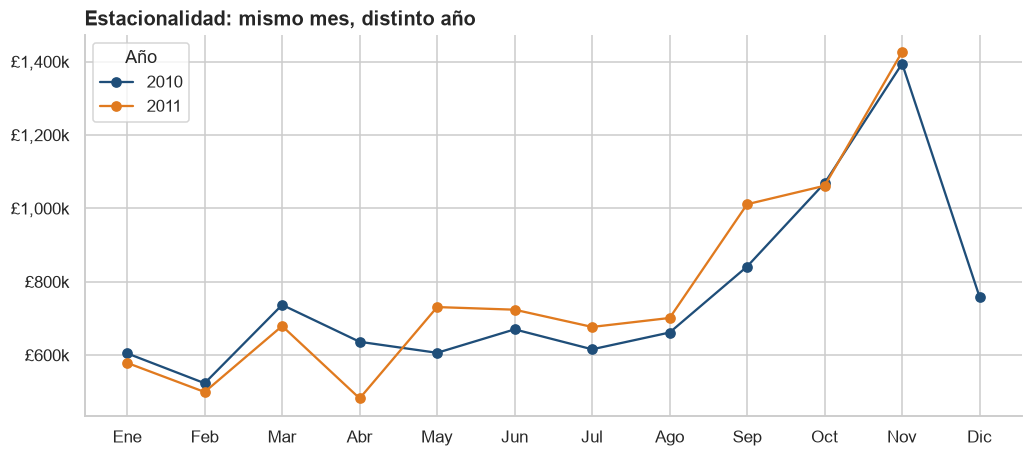

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for anio, color in [(2010, viz.AZUL), (2011, viz.NARANJA)]:
    s = mensual[(mensual["anio"] == anio) & mensual["completo"]]
    ax.plot(s["mes"], s["ventas_netas"], marker="o", label=str(anio), color=color)
ax.set_xticks(range(1, 13), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("Estacionalidad: mismo mes, distinto año")
viz.formato_libras(ax)
ax.legend(title="Año")
viz.guardar(fig, "eda_estacionalidad_interanual")
plt.show()

**Hallazgos.**
- El negocio es **muy estacional**: septiembre, octubre y noviembre concentran el **36,8 %** de las ventas de los meses completos. Noviembre es el pico en ambos años (£1,39 M en 2010 y £1,43 M en 2011).
- Entre enero y noviembre las ventas crecieron solo **2,5 %** (de £8,36 M a £8,57 M): el negocio es estable, no está en expansión.
- La mayor caída es **abril de 2011 (−24 %)**, que se recupera en mayo (+21 %). Es una variación puntual que conviene revisar con el negocio.
- *Implicación:* el inventario debe prepararse desde agosto para la temporada alta, y el modelo de demanda necesita variables de estacionalidad.

## 3. Días, horas y festivos

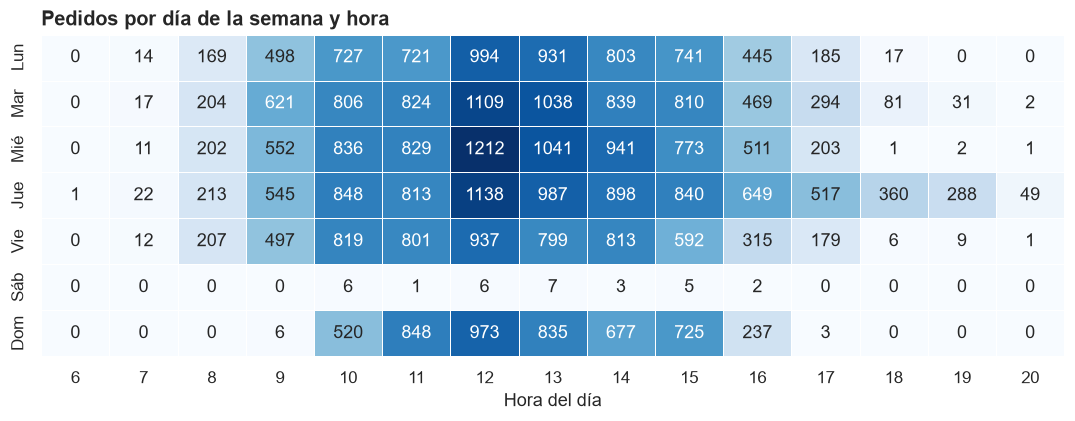

Participación de ventas por día: {'Lun': 17.6, 'Mar': 19.6, 'Mié': 17.4, 'Jue': 20.7, 'Vie': 15.5, 'Sáb': 0.1, 'Dom': 9.2}
Hora pico (más pedidos): 12 h


In [7]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
calor = (v.groupby(["dia_semana", "hora"])["factura"].nunique().unstack(fill_value=0))
calor.index = [dias[i] for i in calor.index]
fig, ax = plt.subplots(figsize=(12, 3.8))
viz.mapa_calor(calor, "Pedidos por día de la semana y hora", ax=ax, cbar=False)
ax.set_xlabel("Hora del día"); ax.set_ylabel("")
viz.guardar(fig, "eda_pedidos_dia_hora")
plt.show()
por_dia = v.groupby("dia_semana")["importe"].sum()
print("Participación de ventas por día:", (por_dia / por_dia.sum() * 100).round(1).rename(lambda i: dias[i]).to_dict())
print("Hora pico (más pedidos):", calor.sum().idxmax(), "h")

In [8]:
# ¿Se vende en festivos? Promedio diario en días hábiles (lun-vie) con y sin festivo
diario = v.groupby("fecha")["importe"].sum().reset_index()
calendario = pd.DataFrame({"fecha": pd.date_range(v["fecha"].min(), v["fecha"].max())})
calendario = calendario.merge(diario, on="fecha", how="left").fillna({"importe": 0})
calendario["festivo"] = calendario["fecha"].isin(festivos["fecha"])
calendario["habil"] = calendario["fecha"].dt.day_of_week < 5
tabla_fest = (calendario[calendario["habil"]].groupby("festivo")["importe"]
              .agg(["count", "mean"]).rename(index={False: "Día hábil normal", True: "Festivo"}))
tabla_fest.columns = ["días", "venta promedio (GBP)"]
print("Días hábiles festivos sin ninguna venta:",
      int(((calendario["festivo"]) & calendario["habil"] & (calendario["importe"] == 0)).sum()), "de",
      int((calendario["festivo"] & calendario["habil"]).sum()))
tabla_fest

Días hábiles festivos sin ninguna venta: 16 de 16


,días,venta promedio (GBP)
festivo,,
Día hábil normal,513,"34,280.05"
Festivo,16,0.00


**Hallazgos.**
- Los pedidos se concentran de **martes a jueves** y entre las **10 y las 15 h**, con pico a las 12 h. El **sábado prácticamente no hay operación** (0,1 % de las ventas) y el domingo sí (9,2 %).
- **Ningún festivo hábil tuvo ventas** (16 de 16 días festivos en lunes a viernes con venta cero): la tienda cierra en festivos. Una semana con festivo tiene un día menos de ventas, por eso el modelo usa el número de festivos de la semana como variable.
- *Implicación:* campañas y atención comercial deben reforzarse a mediodía de martes a jueves; las semanas con festivo deben planearse con menos despachos.

## 4. Concentración de productos (Pareto / ABC)

Productos con ventas: 4,723
El 80 % del ingreso lo generan 1,040 productos (22.0% del catálogo).


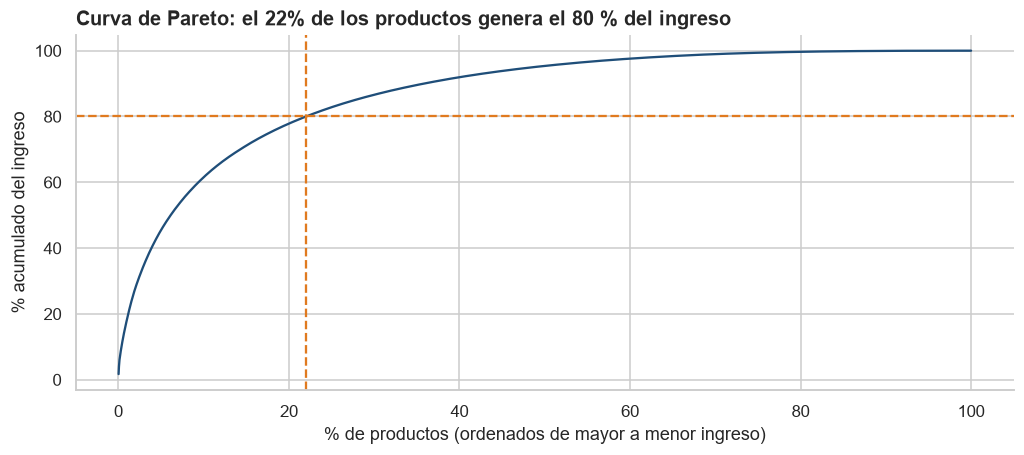

In [9]:
prod = (v.groupby(["codigo_producto", "descripcion"])
        .agg(ingreso=("importe", "sum"), unidades=("cantidad", "sum"), pedidos=("factura", "nunique"))
        .reset_index().sort_values("ingreso", ascending=False))
prod["% acumulado"] = prod["ingreso"].cumsum() / prod["ingreso"].sum() * 100
n80 = (prod["% acumulado"] <= 80).sum() + 1
print(f"Productos con ventas: {len(prod):,}")
print(f"El 80 % del ingreso lo generan {n80:,} productos ({n80/len(prod):.1%} del catálogo).")
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(1, len(prod) + 1) / len(prod) * 100
ax.plot(x, prod["% acumulado"], color=viz.AZUL)
ax.axhline(80, ls="--", color=viz.NARANJA); ax.axvline(n80 / len(prod) * 100, ls="--", color=viz.NARANJA)
ax.set_xlabel("% de productos (ordenados de mayor a menor ingreso)"); ax.set_ylabel("% acumulado del ingreso")
ax.set_title(f"Curva de Pareto: el {n80/len(prod):.0%} de los productos genera el 80 % del ingreso")
viz.guardar(fig, "eda_pareto_productos")
plt.show()

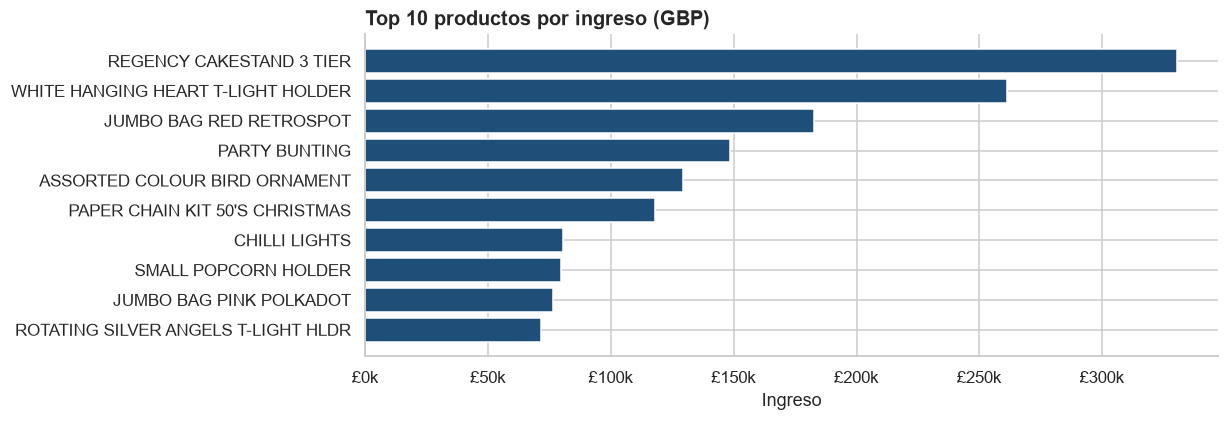

,codigo_producto,descripcion,ingreso,unidades,pedidos
1632,22423,REGENCY CAKESTAND 3 TIER,"330,590.32",26478,3918
4151,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"261,168.73",94719,5464
4129,85099B,JUMBO BAG RED RETROSPOT,"182,680.98",97176,4013
3126,47566,PARTY BUNTING,"148,318.28",28200,2674
3889,84879,ASSORTED COLOUR BIRD ORNAMENT,"129,324.49",80082,2807
1320,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"117,760.29",35084,2018
3390,79321,CHILLI LIGHTS,"80,540.88",15841,1135
1427,22197,SMALL POPCORN HOLDER,"79,520.20",88499,2322
1601,22386,JUMBO BAG PINK POLKADOT,"76,324.62",39437,2245
3531,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,"71,300.40",31409,756


In [10]:
top = prod.head(10).set_index("descripcion")["ingreso"]
viz.barras_horizontales(top, "Top 10 productos por ingreso (GBP)", "Ingreso", libras=True)
viz.guardar(plt.gcf(), "eda_top10_productos")
plt.show()
prod.head(10)[["codigo_producto", "descripcion", "ingreso", "unidades", "pedidos"]]

**Hallazgos.**
- Se cumple el principio de Pareto: el **22 % de los productos (1.040 de 4.723) genera el 80 % del ingreso**. Esos productos son la **clase A** del dashboard y deben tener prioridad de inventario.
- Los productos estrella son decorativos y de fiesta: el *Regency Cakestand 3 Tier* lidera en ingreso (£330.590) y el *White Hanging Heart T-Light Holder* es el más presente en pedidos (5.464).
- Varios de los top están ligados a la Navidad (*Paper Chain Kit 50's Christmas*), lo que refuerza la estacionalidad.

## 5. Clientes

Clientes identificados con compras: 5,852
El 10 % de clientes que más compra aporta el 63.4% del ingreso identificado.
Clientes que compraron más de una vez: 72.3%
Pedidos por cliente (mediana): 3 | gasto total (mediana): £856


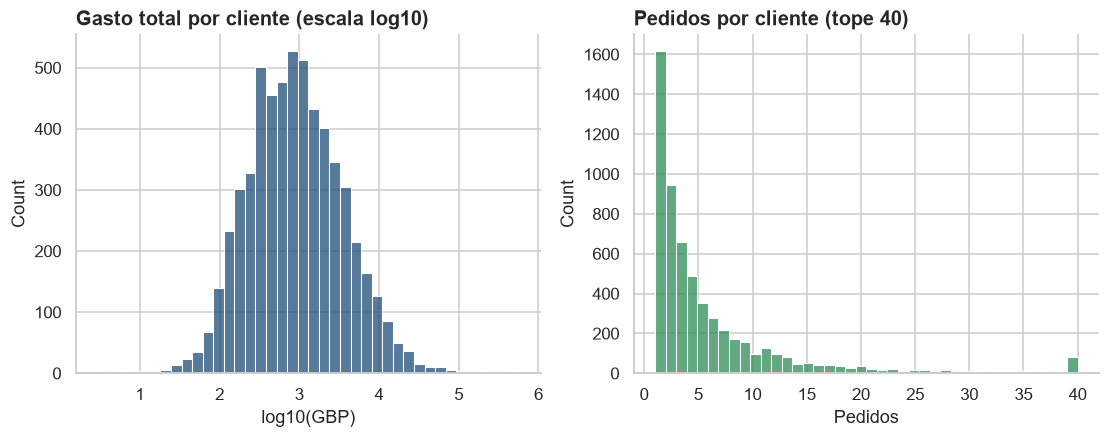

In [11]:
vc = v[v["cliente_registrado"]]
cli = vc.groupby("cliente_id").agg(ingreso=("importe", "sum"), pedidos=("factura", "nunique"),
                                   primera=("fecha", "min"), ultima=("fecha", "max"))
cli = cli.sort_values("ingreso", ascending=False)
top10 = cli["ingreso"].head(int(len(cli) * 0.10)).sum() / cli["ingreso"].sum()
recurrentes = (cli["pedidos"] > 1).mean()
print(f"Clientes identificados con compras: {len(cli):,}")
print(f"El 10 % de clientes que más compra aporta el {top10:.1%} del ingreso identificado.")
print(f"Clientes que compraron más de una vez: {recurrentes:.1%}")
print(f"Pedidos por cliente (mediana): {cli['pedidos'].median():.0f} | gasto total (mediana): £{cli['ingreso'].median():,.0f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log10(cli["ingreso"].clip(lower=1)), bins=40, ax=axes[0], color=viz.AZUL)
axes[0].set_title("Gasto total por cliente (escala log10)"); axes[0].set_xlabel("log10(GBP)")
sns.histplot(cli["pedidos"].clip(upper=40), bins=40, ax=axes[1], color=viz.VERDE)
axes[1].set_title("Pedidos por cliente (tope 40)"); axes[1].set_xlabel("Pedidos")
viz.guardar(fig, "eda_distribucion_clientes")
plt.show()

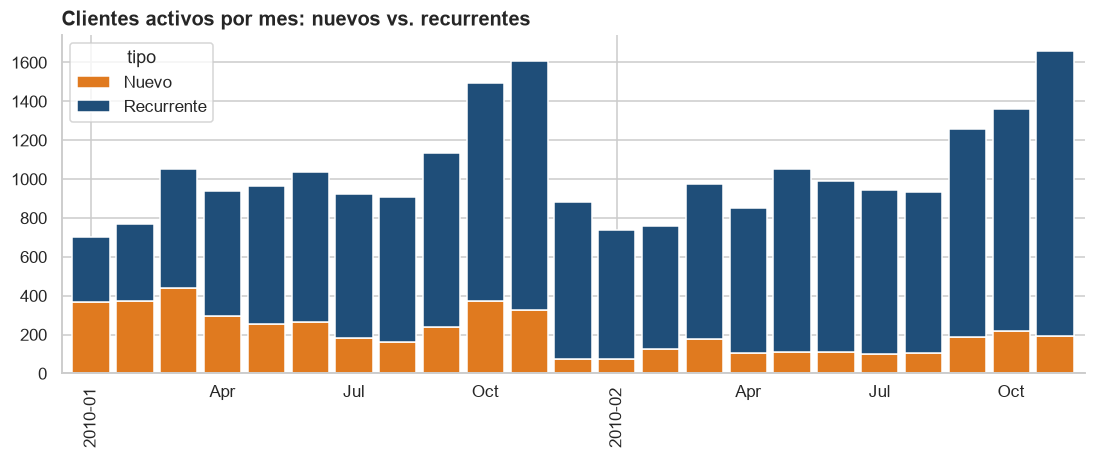

Participación de recurrentes en 2011: 86.9%


In [12]:
# Clientes nuevos vs. recurrentes por mes
primera = vc.groupby("cliente_id")["fecha"].min().dt.to_period("M")
vc_mes = vc.assign(mes=vc["fecha"].dt.to_period("M"), mes_alta=vc["cliente_id"].map(primera))
nuevos = (vc_mes.drop_duplicates(["cliente_id", "mes"])
          .assign(tipo=lambda x: np.where(x["mes"] == x["mes_alta"], "Nuevo", "Recurrente"))
          .groupby(["mes", "tipo"]).size().unstack(fill_value=0))
nuevos = nuevos.iloc[1:-1]  # se quitan dic-2009 (todos 'nuevos' por inicio de datos) y dic-2011 (incompleto)
fig, ax = plt.subplots(figsize=(12, 4))
nuevos.plot(kind="bar", stacked=True, ax=ax, color=[viz.NARANJA, viz.AZUL], width=0.85)
ax.set_title("Clientes activos por mes: nuevos vs. recurrentes"); ax.set_xlabel("")
ax.set_xticklabels([str(p) for p in nuevos.index], rotation=90)
viz.guardar(fig, "eda_clientes_nuevos_recurrentes")
plt.show()
print("Participación de recurrentes en 2011:",
      f"{nuevos.loc[nuevos.index.year == 2011, 'Recurrente'].sum() / nuevos.loc[nuevos.index.year == 2011].sum().sum():.1%}")

**Hallazgos.**
- **Alta concentración:** el 10 % de los clientes que más compra aporta el **63,4 %** del ingreso identificado. Perder a uno de estos clientes tiene un impacto grande.
- **Buena fidelidad:** el **72,3 %** de los clientes compró más de una vez, y en 2011 el **86,9 %** de los clientes activos de cada mes eran recurrentes.
- La mediana es de 3 pedidos y £856 por cliente en dos años.
- *Implicación:* conviene un programa de retención para los clientes de mayor valor (segmentos RFM "Campeones" y "En riesgo" del dashboard).

## 6. Mercados (países y regiones)

Reino Unido: 85.4 % del ingreso.
Internacional: 14.6 % del ingreso en 42 países/orígenes.
Ticket promedio Reino Unido: £457 | internacional: £851


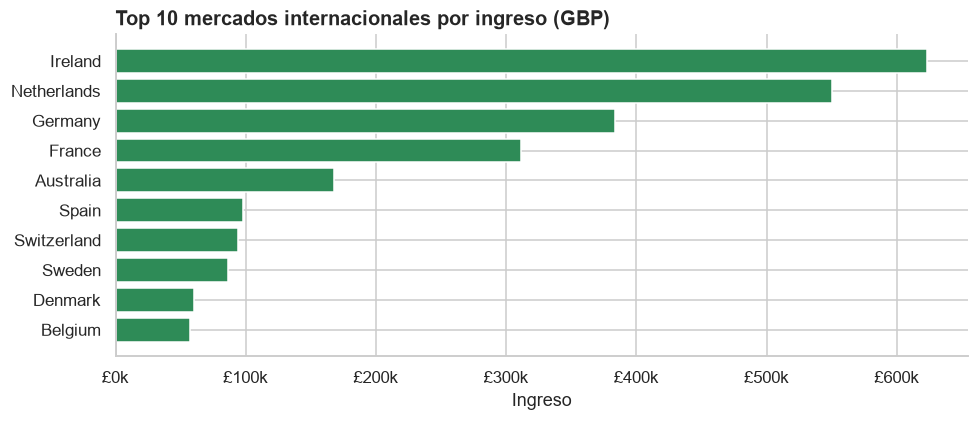

,ingreso,clientes,pedidos,% ingreso,ticket promedio
pais,,,,,
United Kingdom,"16,544,814.30",5335,36181,85.40,457.30
Ireland,"623,414.20",4,581,3.20,"1,073.00"
Netherlands,"549,773.40",22,216,2.80,"2,545.20"
Germany,"383,289.00",107,753,2.00,509.00
France,"311,090.30",94,598,1.60,520.20
Australia,"167,800.00",15,89,0.90,"1,885.40"
Spain,"97,766.80",38,144,0.50,678.90
Switzerland,"94,024.60",23,85,0.50,"1,106.20"
Sweden,"86,319.10",20,99,0.40,871.90


In [13]:
pais = v.groupby("pais").agg(ingreso=("importe", "sum"), clientes=("cliente_id", "nunique"),
                             pedidos=("factura", "nunique")).sort_values("ingreso", ascending=False)
pais["% ingreso"] = pais["ingreso"] / pais["ingreso"].sum() * 100
pais["ticket promedio"] = pais["ingreso"] / pais["pedidos"]
print(f"Reino Unido: {pais.loc['United Kingdom', '% ingreso']:.1f} % del ingreso.")
intl = pais.drop("United Kingdom")
print(f"Internacional: {intl['% ingreso'].sum():.1f} % del ingreso en {len(intl)} países/orígenes.")
print(f"Ticket promedio Reino Unido: £{pais.loc['United Kingdom','ticket promedio']:,.0f} | "
      f"internacional: £{intl['ingreso'].sum()/intl['pedidos'].sum():,.0f}")
viz.barras_horizontales(intl.head(10)["ingreso"], "Top 10 mercados internacionales por ingreso (GBP)", "Ingreso",
                        color=viz.VERDE, libras=True)
viz.guardar(plt.gcf(), "eda_top10_paises")
plt.show()
pais.head(11).round(1)

In [14]:
region = v[v["pais"] != "United Kingdom"].groupby("region")["importe"].sum().sort_values(ascending=False)
(region / region.sum() * 100).round(1).to_frame("% del ingreso internacional")

,% del ingreso internacional
region,
Europa y Asia Central,89.30
Asia Oriental y Pacífico,8.50
Medio Oriente y Norte de África,1.10
América del Norte,0.50
No especificado,0.40
África Subsahariana,0.10
América Latina y el Caribe,0.10


**Hallazgos.**
- El **Reino Unido** aporta el **85,4 %** del ingreso; el mercado internacional, el **14,6 %** repartido en 42 países u orígenes, casi todos europeos (89,3 % del ingreso internacional).
- El **ticket promedio internacional (£851) casi duplica el del Reino Unido (£457)**: los clientes extranjeros compran menos veces pero en mayor volumen.
- **Irlanda** (3,2 %) depende de solo 4 clientes y **Países Bajos** (2,8 %) tiene el ticket más alto (£2.545): son mercados valiosos pero frágiles.
- *Implicación:* hay espacio para crecer en Alemania y Francia, que ya tienen más de 90 clientes cada uno.

## 7. Devoluciones

In [15]:
bruto = v["importe"].sum(); devuelto = -d["importe"].sum()
print(f"Ventas brutas: £{bruto:,.0f} | Devoluciones: £{devuelto:,.0f} | Tasa de devolución: {devuelto/bruto:.2%}")
dev_prod = (pd.DataFrame({"vendido": v.groupby("descripcion")["importe"].sum(),
                          "devuelto": -d.groupby("descripcion")["importe"].sum()})
            .fillna(0).query("vendido > 20000"))
dev_prod["tasa_%"] = dev_prod["devuelto"] / dev_prod["vendido"] * 100
dev_prod.sort_values("tasa_%", ascending=False).head(10).round(1)

Ventas brutas: £19,380,627 | Devoluciones: £470,773 | Tasa de devolución: 2.43%


,vendido,devuelto,tasa_%
descripcion,,,
FAIRY CAKE FLANNEL ASSORTED COLOUR,"25,407.30","6,614.40",26.00
FELTCRAFT DOLL MOLLY,"20,151.00","3,562.80",17.70
TEA TIME PARTY BUNTING,"27,564.80","4,490.50",16.30
COLOUR GLASS. STAR T-LIGHT HOLDER,"44,680.80","7,164.10",16.00
SET/4 WHITE RETRO STORAGE CUBES,"43,845.00","5,187.60",11.80
DOORMAT FAIRY CAKE,"45,723.80","4,678.70",10.20
CERAMIC CAKE STAND + HANGING CAKES,"22,333.30","2,234.20",10.00
PINK BLUE FELT CRAFT TRINKET BOX,"28,581.00","2,739.30",9.60
SMALL GLASS HEART TRINKET POT,"24,641.40","2,296.80",9.30


In [16]:
dev_pais = (pd.DataFrame({"vendido": v.groupby("pais")["importe"].sum(),
                          "devuelto": -d.groupby("pais")["importe"].sum()}).fillna(0)
            .query("vendido > 100000"))
dev_pais["tasa_%"] = dev_pais["devuelto"] / dev_pais["vendido"] * 100
dev_pais.sort_values("tasa_%", ascending=False).round(1)

,vendido,devuelto,tasa_%
pais,,,
France,"311,090.30","17,659.10",5.70
Ireland,"623,414.20","20,297.60",3.30
United Kingdom,"16,544,814.30","386,423.60",2.30
Germany,"383,289.00","8,715.50",2.30
Australia,"167,800.00","1,517.90",0.90
Netherlands,"549,773.40","3,678.00",0.70


**Hallazgos.**
- La **tasa de devolución global es baja: 2,43 %** del valor vendido (£470.773 de £19,38 M).
- Algunos productos sí tienen tasas altas: *Fairy Cake Flannel Assorted Colour* (26 %), *Feltcraft Doll Molly* (17,7 %) y *Tea Time Party Bunting* (16,3 %). Son candidatos a revisar calidad, empaque o descripción en la web.
- **Francia** tiene la tasa más alta entre los mercados grandes (5,7 %), más del doble que el Reino Unido (2,3 %).

## 8. Correlaciones y valores atípicos

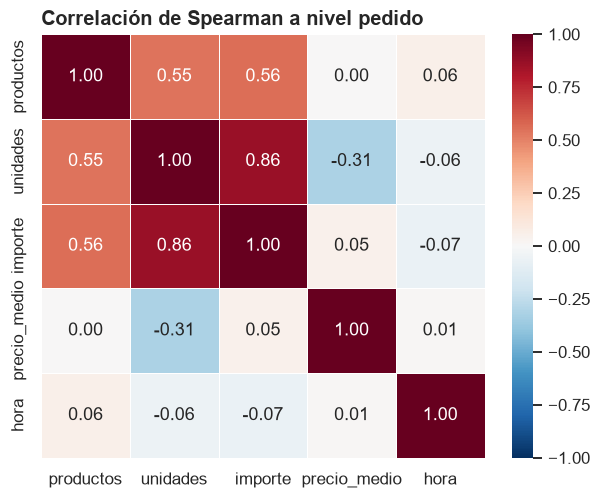

,productos,unidades,importe,precio_medio,hora
productos,1.00,0.55,0.56,0.00,0.06
unidades,0.55,1.00,0.86,-0.31,-0.06
importe,0.56,0.86,1.00,0.05,-0.07
precio_medio,0.00,-0.31,0.05,1.00,0.01
hora,0.06,-0.06,-0.07,0.01,1.00


In [17]:
pedidos_c = pedidos.join(v.groupby("factura")["precio_unitario"].mean().rename("precio_medio"))
pedidos_c["hora"] = v.groupby("factura")["hora"].first()
corr = pedidos_c[["productos", "unidades", "importe", "precio_medio", "hora"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5))
viz.mapa_calor(corr, "Correlación de Spearman a nivel pedido", fmt=".2f", cmap="RdBu_r", ax=ax, vmin=-1, vmax=1)
viz.guardar(fig, "eda_correlaciones")
plt.show()
corr.round(2)

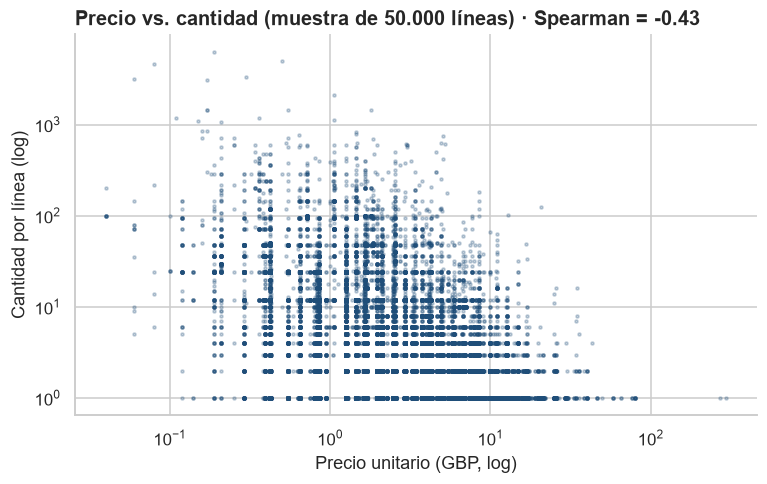

In [18]:
# Relación precio-cantidad por línea: los artículos baratos se compran en mayor volumen
lineas = v.sample(50_000, random_state=config.SEMILLA)
rho = lineas[["precio_unitario", "cantidad"]].corr(method="spearman").iloc[0, 1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(lineas["precio_unitario"], lineas["cantidad"], s=4, alpha=0.25, color=viz.AZUL)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Precio unitario (GBP, log)"); ax.set_ylabel("Cantidad por línea (log)")
ax.set_title(f"Precio vs. cantidad (muestra de 50.000 líneas) · Spearman = {rho:.2f}")
viz.guardar(fig, "eda_precio_vs_cantidad")
plt.show()

In [19]:
# Pedidos atípicos por importe (regla IQR) — se conservan: son mayoristas reales
q1, q3 = pedidos["importe"].quantile([.25, .75])
lim = q3 + 3 * (q3 - q1)
atipicos = pedidos[pedidos["importe"] > lim]
print(f"Límite superior (Q3 + 3·IQR): £{lim:,.0f}")
print(f"Pedidos atípicos: {len(atipicos):,} ({len(atipicos)/len(pedidos):.1%}) que suman el "
      f"{atipicos['importe'].sum()/pedidos['importe'].sum():.1%} del ingreso.")
atipicos.sort_values("importe", ascending=False).head(5)

Límite superior (Q3 + 3·IQR): £1,486
Pedidos atípicos: 1,863 (4.7%) que suman el 34.0% del ingreso.


,fecha,cliente,pais,productos,unidades,importe
factura,,,,,,
574941,2011-11-07,SIN REGISTRO,United Kingdom,101,14149,"52,940.94"
576365,2011-11-14,SIN REGISTRO,United Kingdom,99,13956,"50,653.91"
533027,2010-11-15,SIN REGISTRO,United Kingdom,111,13387,"49,844.99"
531516,2010-11-08,SIN REGISTRO,United Kingdom,115,12410,"45,332.97"
493819,2010-01-07,14156,Ireland,94,25018,"44,051.60"


**Hallazgos.**
- A nivel pedido, el **importe se explica sobre todo por las unidades** (ρ = 0,86) y en menor medida por el número de productos distintos (ρ = 0,56). La hora del pedido no se relaciona con su tamaño.
- **Precio y cantidad se relacionan de forma inversa** (ρ = −0,31 a nivel pedido): los artículos baratos se compran en mayor volumen, comportamiento típico de mayoristas.
- Hay **1.863 pedidos atípicos** por importe (4,7 % del total) que suman el **34 % del ingreso**. No son errores: son compras mayoristas reales, por eso **se conservan**. Los más grandes no tienen cliente identificado, lo que limita su seguimiento comercial.

## 9. ¿Qué tan predecible es la demanda semanal? (insumo para el modelo)

Productos con venta en ≥ 52 semanas: 1,609
Coeficiente de variación semanal (mediana): 1.54  -> la demanda varía alrededor de 154% de su promedio de una semana a otra
Demanda total de la tienda: coeficiente de variación 0.36


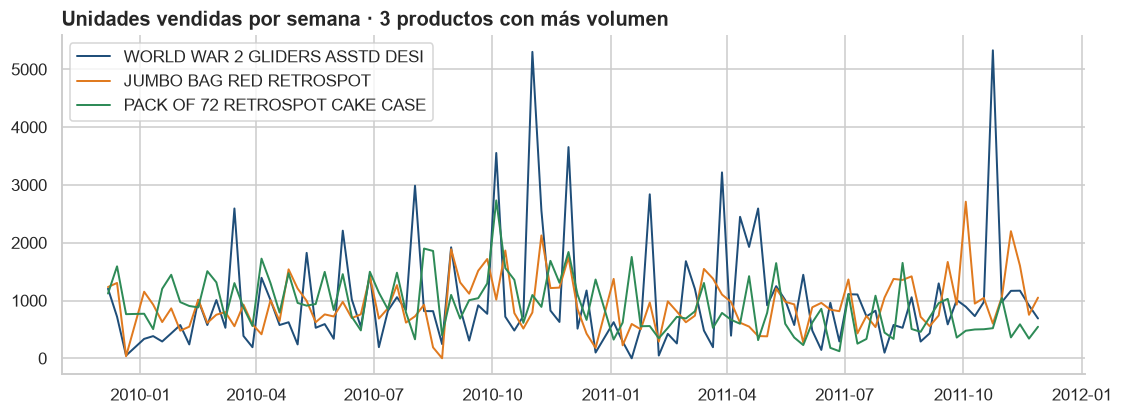

In [20]:
semanal = (v.groupby(["codigo_producto", "semana_inicio"])["cantidad"].sum().unstack(fill_value=0))
semanal = semanal.iloc[:, 1:-1]  # se quitan la primera y la última semana (incompletas)
activos = semanal[(semanal > 0).sum(axis=1) >= 52]  # productos vendidos al menos 52 semanas
cv = (activos.std(axis=1) / activos.mean(axis=1))
print(f"Productos con venta en ≥ 52 semanas: {len(activos):,}")
print(f"Coeficiente de variación semanal (mediana): {cv.median():.2f}  -> la demanda varía alrededor de "
      f"{cv.median():.0%} de su promedio de una semana a otra")
total = semanal.sum()
print(f"Demanda total de la tienda: coeficiente de variación {total.std()/total.mean():.2f}")
fig, ax = plt.subplots(figsize=(12, 4))
ejemplos = activos.sum(axis=1).nlargest(3).index
desc = v.drop_duplicates("codigo_producto").set_index("codigo_producto")["descripcion"]
for c_, col in zip(ejemplos, [viz.AZUL, viz.NARANJA, viz.VERDE]):
    ax.plot(semanal.columns, semanal.loc[c_], label=desc[c_][:30], color=col, lw=1.3)
ax.set_title("Unidades vendidas por semana · 3 productos con más volumen"); ax.legend()
viz.guardar(fig, "eda_demanda_semanal_ejemplos")
plt.show()

**Hallazgos (insumo para el modelo).**
- La demanda semanal **por producto es muy irregular**: el coeficiente de variación mediano es **1,54**. Es decir, de una semana a otra la venta de un producto se aleja en promedio 1,5 veces su propio promedio, por los pedidos mayoristas que llegan de forma esporádica.
- En cambio, la **demanda total de la tienda es mucho más estable** (coeficiente 0,36).
- *Implicación para el modelo:* predecir producto por producto es difícil y el error será alto en términos relativos. El modelo debe compararse contra líneas base simples (repetir la semana anterior, promedio de 4 semanas) y entregar un **rango** de unidades, no solo un número.

## 10. Resumen de hallazgos

| # | Hallazgo | Implicación para el negocio |
|---|---|---|
| 1 | Septiembre a noviembre concentra el 36,8 % de las ventas; noviembre es el pico | Comprar y preparar inventario desde agosto |
| 2 | Crecimiento de solo 2,5 % entre 2010 y 2011 | Buscar crecimiento en mercados internacionales y en retención |
| 3 | El 22 % de los productos genera el 80 % del ingreso | Priorizar inventario y reposición de la clase A |
| 4 | El 10 % de los clientes aporta el 63 % del ingreso | Programa de retención de clientes clave |
| 5 | El ticket internacional es casi el doble del británico | Explorar Alemania y Francia, que ya tienen base de clientes |
| 6 | Devolución global baja (2,4 %), con productos puntuales por encima del 15 % | Revisar calidad o descripción de esos productos |
| 7 | Sin ventas en festivos ni sábados; pico de martes a jueves a mediodía | Ajustar logística y atención a ese calendario |
| 8 | Demanda por producto muy irregular (CV 1,54) | El modelo debe dar rangos y superar líneas base simples |